# 4ª entrega 

Integrantes: Erica Blanco, Francesca Matias. 


## Aprendizaje no supervisado: segmentación de clientes con K-means



**Objetivo:** descubrir grupos de clientes del banco con características parecidas, **sin usar la variable exited**, describir el perfil de cada grupo y comprobar si algunos grupos tienen más abandono que otros.

## 1. Carga de datos

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

df = pd.read_csv("Churn_Modelling.csv")

df = df.rename(columns={
    'CreditScore': 'credit_score', 'Geography': 'geography', 'Gender': 'gender',
    'Age': 'age', 'Tenure': 'tenure', 'Balance': 'balance',
    'NumOfProducts': 'num_of_products', 'HasCrCard': 'has_cr_card',
    'IsActiveMember': 'is_active_member', 'EstimatedSalary': 'estimated_salary',
    'Exited': 'exited'})

df = df.drop(columns=['RowNumber', 'CustomerId', 'Surname'])
df.shape

(10000, 11)

## 2. AED para clustering

Elegimos las variables candidatas y miramos cómo se distribuyen y cómo se relacionan entre sí. En clustering no hace falta separar train y test: no hay un objetivo que predecir, queremos describir a todos los clientes.

In [2]:
variables = ['credit_score', 'age', 'tenure', 'balance', 'estimated_salary',
             'num_of_products', 'has_cr_card', 'is_active_member']

df[variables].describe().round(2)

,credit_score,age,tenure,balance,estimated_salary,num_of_products,has_cr_card,is_active_member
count,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00
mean,650.53,38.92,5.01,76485.89,100090.24,1.53,0.71,0.52
std,96.65,10.49,2.89,62397.41,57510.49,0.58,0.46,0.50
min,350.00,18.00,0.00,0.00,11.58,1.00,0.00,0.00
25%,584.00,32.00,3.00,0.00,51002.11,1.00,0.00,0.00
50%,652.00,37.00,5.00,97198.54,100193.92,1.00,1.00,1.00
75%,718.00,44.00,7.00,127644.24,149388.25,2.00,1.00,1.00
max,850.00,92.00,10.00,250898.09,199992.48,4.00,1.00,1.00


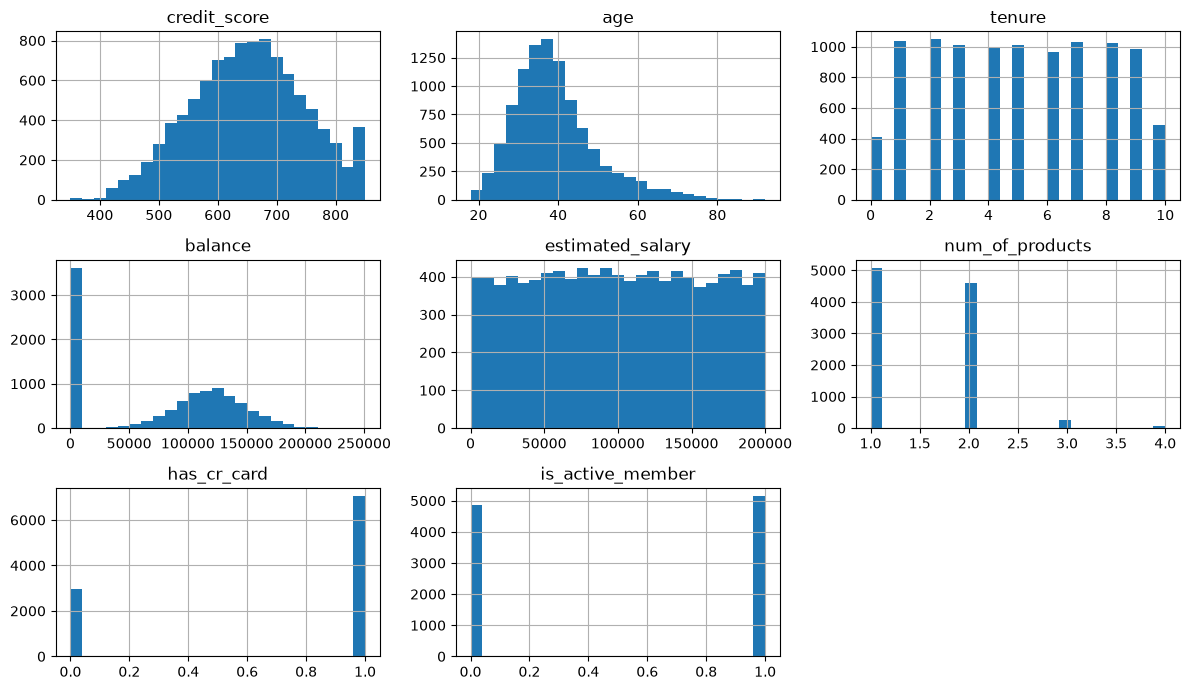

In [3]:
df[variables].hist(bins=25, figsize=(12, 7))
plt.tight_layout()
plt.show()

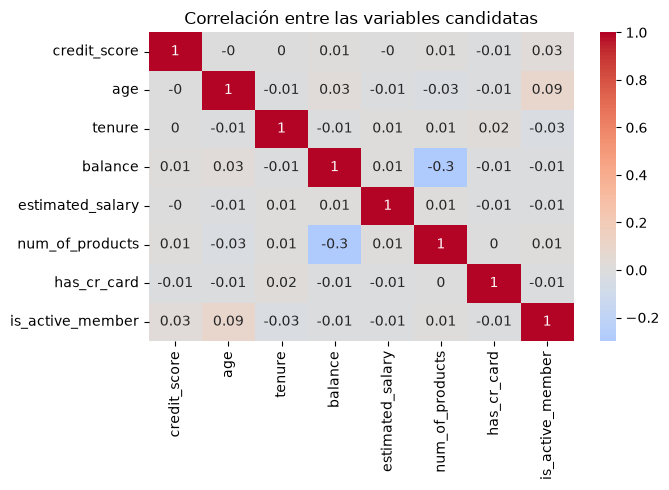

In [4]:
plt.figure(figsize=(7, 5))
sns.heatmap(df[variables].corr().round(2), annot=True, cmap='coolwarm', center=0)
plt.title('Correlación entre las variables candidatas')
plt.tight_layout()
plt.show()

- `balance` tiene muchos clientes en 0.
- `credit_score`, `tenure` y `estimated_salary`: tenure y estimated_salary se reparten casi parejo, sin una forma definida. credit_score tiene forma de campana
- Las correlaciones entre variables son bajas en general: esto sugiere que los grupos no van a estar muy separados y que credit_score, tenure, estimated_salary y has_cr_card aportan poca estructura, lo que justifica probar un conjunto reducido sin ellas.

## 3. Modelo inicial

Como punto de partida usamos **todas** las variables candidatas y un `k=3` elegido "a ojo". Es la referencia contra la que vamos a medir la mejora.

El **coeficiente de silhouette** va de -1 a 1: cuanto más cerca de 1, más parecidos son los clientes dentro de su grupo y más distintos de los otros grupos. Valores alrededor de 0.2 a 0.4 indican grupos poco separados, que es lo normal en datos de clientes.

In [5]:
X_esc = StandardScaler().fit_transform(df[variables])

km_inicial = KMeans(n_clusters=3, n_init=10, random_state=42).fit(X_esc)

sil_inicial = silhouette_score(X_esc, km_inicial.labels_)
print(f"Modelo inicial (8 variables, k=3): silhouette = {sil_inicial:.3f}")
print("Clientes por grupo:")
print(pd.Series(km_inicial.labels_).value_counts().sort_index())

Modelo inicial (8 variables, k=3): silhouette = 0.137
Clientes por grupo:
0    2940
1    4089
2    2971
Name: count, dtype: int64


## 4. Mejora: elegir `k` y las variables

Probamos dos conjuntos de variables y `k` de 2 a 8:
- **completo:** las 8 variables.
- **reducido:** solo `age`, `balance`, `num_of_products` e `is_active_member`, que son las que en el AED mostraron relación con el comportamiento del cliente. Las demás (`credit_score`, `tenure`, `estimated_salary`, `has_cr_card`) se reparten casi parejo y pueden agregar ruido a las distancias.

Para cada combinación calculamos la **inercia** (suma de las distancias de los clientes a su centro; siempre baja al aumentar `k`, por eso se busca el "codo") y el **silhouette**.

In [6]:
conjuntos = {
    'completo': variables,
    'reducido': ['age', 'balance', 'num_of_products', 'is_active_member'],
}

resultados = []
for nombre, cols in conjuntos.items():
    X_c = StandardScaler().fit_transform(df[cols])
    for k in range(2, 9):
        km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_c)
        resultados.append({'conjunto': nombre, 'k': k,
                           'inercia': km.inertia_,
                           'silhouette': silhouette_score(X_c, km.labels_)})

res = pd.DataFrame(resultados)
res.round(3)

,conjunto,k,inercia,silhouette
0,completo,2,69854.257,0.133
1,completo,3,62825.343,0.137
2,completo,4,58292.873,0.122
3,completo,5,54893.040,0.125
4,completo,6,52183.892,0.145
5,completo,7,49773.113,0.140
6,completo,8,47985.836,0.152
7,reducido,2,29860.187,0.274
8,reducido,3,23506.495,0.302
9,reducido,4,19589.557,0.318


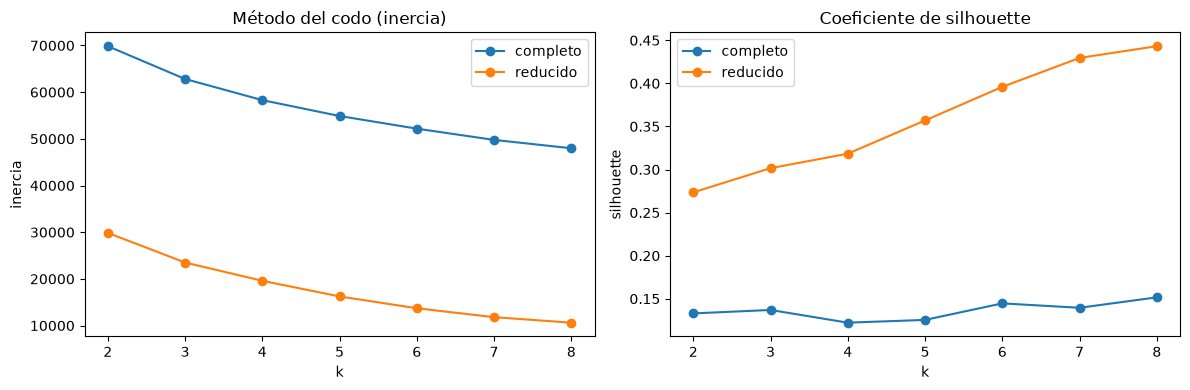

In [7]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 4))

for nombre in conjuntos:
    datos = res[res['conjunto'] == nombre]
    ejes[0].plot(datos['k'], datos['inercia'], marker='o', label=nombre)
    ejes[1].plot(datos['k'], datos['silhouette'], marker='o', label=nombre)

ejes[0].set_title('Método del codo (inercia)')
ejes[0].set_xlabel('k')
ejes[0].set_ylabel('inercia')
ejes[1].set_title('Coeficiente de silhouette')
ejes[1].set_xlabel('k')
ejes[1].set_ylabel('silhouette')
for eje in ejes:
    eje.legend()
plt.tight_layout()
plt.show()

- Qué conjunto de variables tiene mejor silhouette? ¿Por cuánto?
El conjunto reducido (age, balance, num_of_products, is_active_member) tiene un silhouette mucho mejor que el completo para todos los k. Entre k=3 y k=6, el completo va de 0.122 a 0.145 y el reducido de 0.302 a 0.396. Con k=6, que es el que elegimos, la diferencia es de 0.251 (0.396 contra 0.145).
- En qué `k` está el mejor silhouette entre 3 y 6? 
En la inercia no hay un codo marcado: baja de forma gradual en los dos conjuntos. En el reducido, el silhouette sube con cada k, así que tampoco marca un pico claro. Dentro del rango que fijamos (k de 3 a 6), el mayor silhouette es el de k=6 (0.396), por lo que lo elegimos aplicando el criterio, y no porque coincida con un codo. Verificamos además que los grupos sean interpretables y que ninguno tenga menos del 5% de los clientes (el más chico tiene 9.6%).
- Comparabilidad: Los silhouette de un conjunto de 8 variables y uno de 4 no son estrictamente comparables, porque con menos dimensiones es más fácil que los grupos se vean separados.

## 5. Modelo final

Aplicamos el criterio: mayor silhouette entre `k=3` y `k=6`. El código lo calcula, pero se puede fijar a mano si el análisis de la sección anterior lleva a otra elección (por ejemplo, si el mejor `k` deja un grupo con menos del 5% de los clientes).

In [8]:
candidatos = res[(res['k'] >= 3) & (res['k'] <= 6)]
mejor = candidatos.loc[candidatos['silhouette'].idxmax()]

CONJUNTO = mejor['conjunto']   # para fijar a mano: CONJUNTO = 'reducido'
K = int(mejor['k'])            # para fijar a mano: K = 4

print(f"Elegimos el conjunto '{CONJUNTO}' con k = {K} (silhouette = {mejor['silhouette']:.3f})")

Elegimos el conjunto 'reducido' con k = 6 (silhouette = 0.396)


In [9]:
cols_finales = conjuntos[CONJUNTO]
X_final = StandardScaler().fit_transform(df[cols_finales])

km_final = KMeans(n_clusters=K, n_init=10, random_state=42).fit(X_final)

df_cl = df.copy()
df_cl['cluster'] = km_final.labels_

sil_final = silhouette_score(X_final, km_final.labels_)

pd.DataFrame({
    'modelo': ['Inicial (completo, k=3)', f'Final ({CONJUNTO}, k={K})'],
    'silhouette': [round(sil_inicial, 3), round(sil_final, 3)],
}).set_index('modelo')

,silhouette
modelo,
"Inicial (completo, k=3)",0.137
"Final (reducido, k=6)",0.396


## 6. Interpretación de los grupos

Ahora sí usamos `exited`: no para armar los grupos, sino para ver si los grupos que encontró K-means se comportan distinto frente al abandono. Si lo hacen, la segmentación es útil para el banco.

In [10]:
perfil = df_cl.groupby('cluster').agg(
    clientes=('age', 'size'),
    edad=('age', 'mean'),
    saldo=('balance', 'mean'),
    productos=('num_of_products', 'mean'),
    activos=('is_active_member', 'mean'),
    puntaje_crediticio=('credit_score', 'mean'),
    antiguedad=('tenure', 'mean'),
    salario=('estimated_salary', 'mean'),
    churn=('exited', 'mean'),
)
perfil['% de clientes'] = perfil['clientes'] / len(df_cl) * 100
perfil['churn %'] = perfil['churn'] * 100
perfil = perfil.drop(columns='churn')

perfil.round(2)

,clientes,edad,saldo,productos,activos,puntaje_crediticio,antiguedad,salario,% de clientes,churn %
cluster,,,,,,,,,,
0,1734,35.80,5350.23,1.84,1.00,649.38,5.07,99737.07,17.34,8.19
1,2496,35.44,122196.67,1.31,1.00,655.29,4.83,100164.00,24.96,12.42
2,1098,38.11,121383.90,2.24,0.07,650.34,5.15,102390.04,10.98,31.06
3,1983,38.05,121346.20,1.00,0.00,647.20,5.08,101658.03,19.83,32.53
4,958,60.92,78468.81,1.40,0.88,651.26,4.94,96264.80,9.58,32.25
5,1731,36.40,864.56,1.77,0.00,648.34,5.10,99199.96,17.31,16.75


In [11]:
# Cuántos clientes de cada grupo se fueron (1) y cuántos no (0)
pd.crosstab(df_cl['cluster'], df_cl['exited'])

exited,0,1
cluster,,
0,1592,142
1,2186,310
2,757,341
3,1338,645
4,649,309
5,1441,290


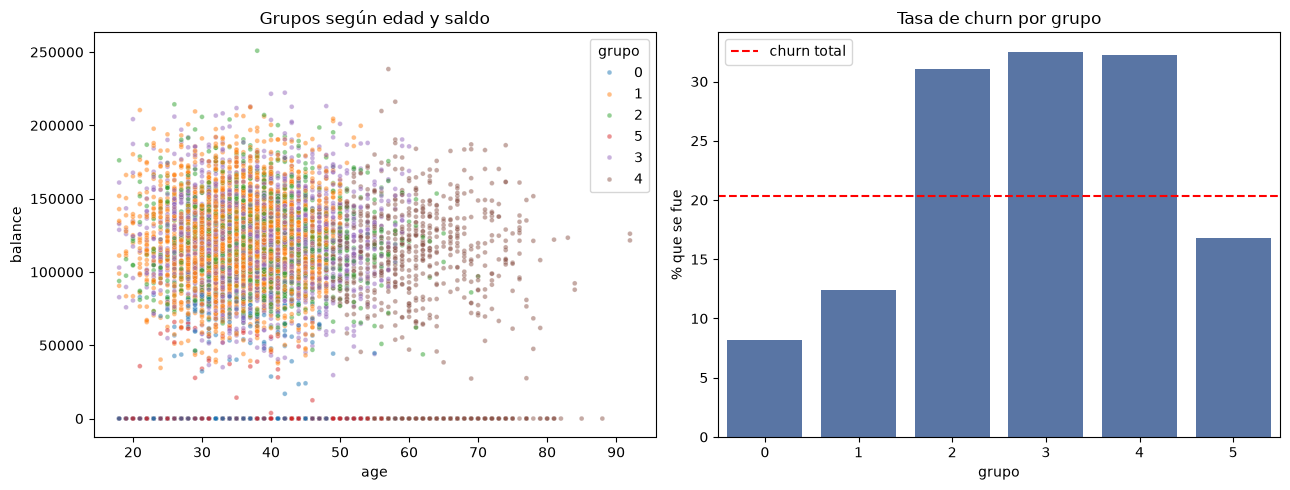

In [12]:
fig, ejes = plt.subplots(1, 2, figsize=(13, 5))

sns.scatterplot(data=df_cl, x='age', y='balance', hue=df_cl['cluster'].astype(str),
                palette='tab10', alpha=0.5, s=12, ax=ejes[0])
ejes[0].set_title('Grupos según edad y saldo')
ejes[0].legend(title='grupo')

sns.barplot(x=perfil.index, y=perfil['churn %'], color='#4C72B0', ax=ejes[1])
ejes[1].axhline(df_cl['exited'].mean() * 100, color='red', linestyle='--', label='churn total')
ejes[1].set_title('Tasa de churn por grupo')
ejes[1].set_xlabel('grupo')
ejes[1].set_ylabel('% que se fue')
ejes[1].legend()

plt.tight_layout()
plt.show()

# Tabla de clusters
 | Grupo | Clientes | Perfil | Churn |
 |-------|----------|--------|-------|
 | 0 | 17.3% | Activos, ~36 años, saldo casi nulo, ~2 productos | 8.2% |
 | 1 | 25.0% | Activos, ~35 años, con saldo (~122.000), pocos productos (1.3) | 12.4% |
 | 2 | 11.0% | Inactivos, con saldo, 2 o más productos | 31.1% |
 | 3 | 19.8% | Inactivos, con saldo, un solo producto | 32.5% |
 | 4 | 9.6% | Mayores (~61 años), casi todos activos, saldo medio | 32.3% |
 | 5 | 17.3% | Inactivos, ~36 años, sin saldo | 16.8% |

El churn total es de 20.4% (2.037 de 10.000 clientes). Los grupos 2, 3 y 4 están por encima: son el 40% de los clientes pero concentran el 64% de los que se van (1.295 de 2.037). Los grupos 0, 1 y 5 están por debajo. El factor que más separa los grupos es ser miembro activo o no, seguido de la edad y de tener saldo. Para el banco, esto indica a quiénes priorizar para campañas de retención: los clientes inactivos con saldo y los clientes mayores.

## 7. Comparación con DBSCAN

Ahora veamos con DBSCAN sobre los mismos datos escalados para justificar la elección de algoritmo. DBSCAN no necesita que le indiquemos el número de grupos: agrupa por densidad y marca como ruido (`-1`) los puntos que no encajan en ningún grupo. Usamos los mismos valores que en clase (`eps=1.2`, `min_samples=10`).

In [13]:
from sklearn.cluster import DBSCAN

dbscan = DBSCAN(eps=1.2, min_samples=10).fit(X_final)
df_cl['cluster_dbscan'] = dbscan.labels_

n_ruido = (df_cl['cluster_dbscan'] == -1).sum()
n_grupos = df_cl.loc[df_cl['cluster_dbscan'] != -1, 'cluster_dbscan'].nunique()

print("Grupos que encuentra DBSCAN:", n_grupos)
print("Clientes marcados como ruido:", n_ruido, "de", len(df_cl))
print()
print("Clientes por grupo (-1 es ruido):")
print(df_cl['cluster_dbscan'].value_counts().sort_index())

Grupos que encuentra DBSCAN: 8
Clientes marcados como ruido: 10 de 10000

Clientes por grupo (-1 es ruido):
cluster_dbscan
-1      10
 0    2563
 1     153
 2    2144
 3    2445
 4    2521
 5      31
 6     112
 7      21
Name: count, dtype: int64


Viendo el resultado de DBSCAN encontró 8 grupos y marcó solo 10 clientes como ruido. Sin embargo, 4 de esos grupos son muy chicos (153, 112, 31 y 21 clientes, menos del 2% cada uno): son demasiado pequeños para armar una campaña o describir un perfil, y no cumplen nuestro criterio de que cada grupo tenga al menos 5% de los clientes. Los otros 4 son grandes (entre 2.100 y 2.600 clientes). En cambio, K-means da 6 grupos con tamaños razonables (entre 9.6% y 25.0% de los clientes), cada uno con un perfil que se puede describir y un nivel de churn distinto. Por eso nos quedamos con K-means. Cabe aclarar que no ajustamos eps ni min_samples, así que con otros valores DBSCAN podría dar otro resultado.

## 8. Conclusiones

1. Elegimos K-means porque es simple, se explica fácil y permite elegir la cantidad de grupos. Probamos DBSCAN y encontró 8 grupos, 4 de ellos con menos de 2% de los clientes, por lo que no sirven para segmentar. Usamos variables numéricas y binarias que describen al cliente, sin exited (que se usó recién al final para interpretar) ni las categorías de texto. Escalamos las variables y elegimos k con el mayor silhouette entre 3 y 6, ya que ni el codo ni el silhouette marcaron un punto claro.
2. Que se mejoró? El silhouette pasó de 0.137 (modelo inicial, 8 variables y k=3) a 0.396 (modelo final, 4 variables y k=6). La mejora se explica por sacar credit_score, tenure, estimated_salary y has_cr_card, que se repartían casi parejo y no se relacionaban con las demás variables (las correlaciones eran casi nulas), y por usar k=6 en lugar de 3.
3. Grupos encontrados(6):
   0- activos sin saldo y con 2 productos (17.3% de los clientes)
   1- activos con saldo (25.0%)
   2- inactivos con saldo y 2 o más productos (11.0%)
   3- inactivos con saldo y un solo producto (19.8%)
   4- mayores, de ~61 años (9.6%)
   5- inactivos sin saldo (17.3%)
4. Relación con el abandono: El churn total es 20.4%. Los grupos 2, 3 y 4 tienen un churn de 31% a 33%: son el 40% de los clientes y concentran el 64% de los que se van (1.295 de 2.037). Los grupos 0, 1 y 5 están por debajo del total (8% a 17%). El banco podría priorizar acciones de retención en los clientes inactivos con saldo y en los clientes mayores, que son los de mayor riesgo.
5. Limitaciones:
Los silhouette son moderados: los grupos se superponen y no están claramente separados.
El silhouette alto del conjunto reducido está influido por variables binarias y discretas (is_active_member, num_of_products, saldo en cero), que forman bloques naturales. Y no se puede comparar estrictamente con el del conjunto completo, porque tienen distinta cantidad de variables.
K-means asume grupos de forma más o menos esférica y de tamaño parecido, y es sensible a la escala y a los valores extremos.
Los resultados dependen de la semilla (random_state); usamos n_init=10 para reducir ese efecto.